<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/Artificial_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Implementation of Artificial Neural Network (ANN) with Backpropagation

We will implement a simple feedforward neural network from scratch using `numpy`. This includes:
1. **Forward Propagation**: Computing predictions.
2. **Backpropagation**: Computing gradients using the chain rule.
3. **Gradient Descent**: Updating weights and biases.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
np.random.seed(42)

# Define activation functions and their derivatives
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    sx = sigmoid(x)
    return sx * (1 - sx)

class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.1):
        self.lr = learning_rate

        # Initialize weights and biases
        self.W1 = np.random.randn(input_size, hidden_size) * 0.01
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.01
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        self.X = X
        # Hidden layer
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = sigmoid(self.Z1)
        # Output layer
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    def backward(self, y):
        m = y.shape[0]

        # Output layer error and gradient
        dZ2 = self.A2 - y
        dW2 = np.dot(self.A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer error and gradient
        dZ1 = np.dot(dZ2, self.W2.T) * sigmoid_derivative(self.Z1)
        dW1 = np.dot(self.X.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        # Update parameters
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def fit(self, X, y, epochs=1000):
        loss_history = []
        for epoch in range(epochs):
            output = self.forward(X)
            # Binary Cross Entropy Loss
            loss = -np.mean(y * np.log(output + 1e-15) + (1 - y) * np.log(1 - output + 1e-15))
            loss_history.append(loss)

            self.backward(y)

            if epoch % (epochs // 10) == 0:
                print(f"Epoch {epoch}/{epochs} - Loss: {loss:.4f}")
        return loss_history

    def predict(self, X):
        probabilities = self.forward(X)
        return (probabilities > 0.5).astype(int)

### Testing on an Appropriate Dataset

We will use a non-linearly separable synthetic dataset (Moons dataset) to demonstrate the learning capability of our custom ANN.

In [2]:
# Generate dataset
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
y = y.reshape(-1, 1)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate and train the model
nn = NeuralNetwork(input_size=2, hidden_size=8, output_size=1, learning_rate=0.5)
loss_history = nn.fit(X_train, y_train, epochs=2000)

# Evaluate the model
predictions = nn.predict(X_test)
accuracy = np.mean(predictions == y_test)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

Epoch 0/2000 - Loss: 0.6932
Epoch 200/2000 - Loss: 0.3444
Epoch 400/2000 - Loss: 0.2917
Epoch 600/2000 - Loss: 0.2904
Epoch 800/2000 - Loss: 0.2899
Epoch 1000/2000 - Loss: 0.2896
Epoch 1200/2000 - Loss: 0.2894
Epoch 1400/2000 - Loss: 0.2891
Epoch 1600/2000 - Loss: 0.2889
Epoch 1800/2000 - Loss: 0.2888

Test Accuracy: 86.00%


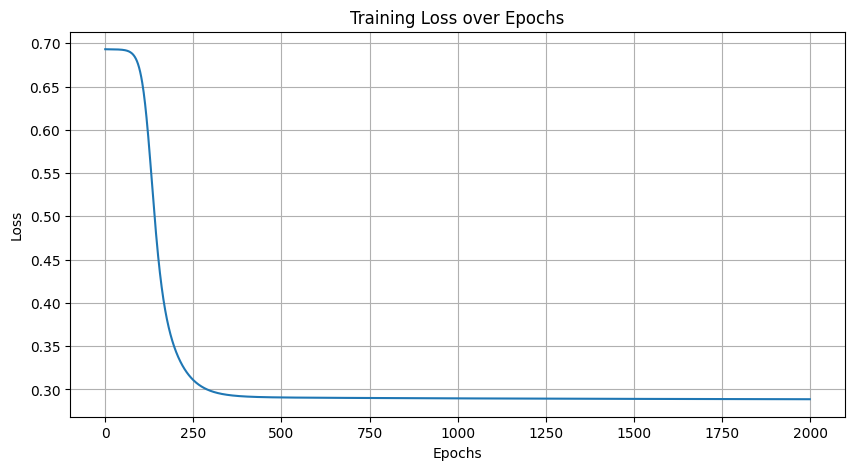

In [3]:
# Plot learning curve
plt.figure(figsize=(10, 5))
plt.plot(loss_history)
plt.title('Training Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()